In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
df = pd.read_csv('dataset.csv')

## עמודה N: vehicle_type
עמודה קטגוריאלית המציגה 6 סוגי רכבים המופיעים בדאטה.סוג הרכב ידוע ביום החתימה על ההסכם ולכן אין דליפת מידע. 

נבדוק את מספרי הנהגים בכל רכב, ערכים חסרים, ואת השפעת העמודה על משתנה המטרה

In [2]:
# בדיקת ערכים חסרים ורשימת סוגי הרכב עם מספר הנהגים בכל אחד

print("Missing:", df["vehicle_type"].isna().sum())
df["vehicle_type"].value_counts()

Missing: 0


vehicle_type
sedan         13916
small         12227
suv           10960
motorcycle     3072
pickup         2985
sports         1840
Name: count, dtype: int64

In [3]:
# השוואת עלות התביעות בין סוגי הרכב לפי שלושה מדדים
df.groupby("vehicle_type")["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3).sort_values("avg_cost")

,avg_cost,share_with_claim,share_expensive,drivers
vehicle_type,,,,
small,1175.473,0.319,0.015,12227
sedan,2549.068,0.341,0.075,13916
motorcycle,2876.179,0.485,0.079,3072
suv,4051.931,0.338,0.143,10960
pickup,6483.999,0.435,0.214,2985
sports,8066.855,0.362,0.261,1840


### מסקנה לגבי vehicle_type
העמודה נקייה, עם פורמט אחיד וללא ערכים חסרים. יש הבדל גדול בעלות בין סוגי הרכב, פי 6.9 בין רכב קטן לרכב ספורט, העמודה תישאר.
סוגי הרכב שונים גם בתדירות התביעות וגם בחומרה. לאופנועים יש הכי הרבה תביעות (48.5%) אך מעט נהגים יקרים (7.9%). לרכבי ספורט יש אחוז תביעות רגיל (36%) אך הכי הרבה נהגים יקרים (26.1%).
לטנדרים יש גם הרבה תביעות וגם הרבה נהגים יקרים. ההשערה שלנו: טנדר הוא רכב עבודה שנוסעים בו הרבה, ולכן ייתכן שחלק מההשפעה שלו היא בעצם השפעה של סוג השימוש, נבדוק זאת בעמודה usage_type.

חוק: איחוד כתיבה, וערך שאינו אחד מששת הסוגים החוקיים הופך לחסר.

## עמודה O: vehicle_age
גיל הרכב בשנים. זו עמודה מספרית שידועה ביום החתימה ולכן אין כאן דליפת מידע.

נבדוק ערכים חסרים וערכים לא הגיוניים, את צורת ההתפלגות ואת הקשר לעלות התביעות.

In [4]:
# בדיקת ערכים חסרים וסטטיסטיקה תיאורית של גיל הרכב
print("Missing:", df["vehicle_age"].isna().sum())
df["vehicle_age"].describe().round(1)

Missing: 0


count    45000.0
mean         7.6
std          5.3
min          0.0
25%          4.0
50%          6.0
75%         10.0
max         25.0
Name: vehicle_age, dtype: float64

הממוצע גבוה מהחציון, נבדוק כמה רכבים יש בכל גיל והאם יש ערכים חריגים

In [5]:
# מספר הרכבים בכל גיל מסודר לפי הגיל.
df["vehicle_age"].value_counts().sort_index()

vehicle_age
0      723
1     2269
2     3489
3     4037
4     4176
5     4099
6     3862
7     3478
8     3017
9     2606
10    2241
11    1943
12    1652
13    1286
14    1158
15     875
16     786
17     606
18     498
19     414
20     312
21     268
22     249
23     185
24     163
25     608
Name: count, dtype: int64

In [6]:
# חלוקת הרכבים לחמש קבוצות שוות לפי גיל הרכב והשוואת עלות התביעות בין הקבוצות
age_group = pd.qcut(df["vehicle_age"], 5)
df.groupby(age_group, observed=True)["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
vehicle_age,,,,
"(-0.001, 3.0]",4180.330,0.308,0.143,10518
"(3.0, 5.0]",3569.221,0.331,0.118,8275
"(5.0, 8.0]",3040.877,0.341,0.091,10357
"(8.0, 12.0]",2326.196,0.379,0.058,8442
"(12.0, 25.0]",1707.849,0.415,0.034,7408


אנו רואים שיש קפיצה גדולה בכמות הנהגים בין רכבים בני 24 ל25 שנים.
נבדוק האם לגיל 25 יש השפעה שונה מבחינת התדירות או החומרה של התביעות

In [7]:
# השוואת עלות התביעות בגילאי הרכב הגבוהים, כדי לבדוק אם גיל 25 שונה מהגילאים שלפניו
old_cars = df[df["vehicle_age"] >= 20]
old_cars.groupby("vehicle_age")["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,drivers
vehicle_age,,,
20,1698.798,0.458,312
21,1855.563,0.381,268
22,1491.189,0.446,249
23,1381.708,0.427,185
24,1366.006,0.405,163
25,1767.804,0.479,608


### מסקנה לגבי vehicle_age
העמודה נקייה, עם ערכים שלמים בין 0 ל-25 וללא ערכים חסרים. ההתפלגות מוטה ימינה (ממוצע 7.6, חציון 6): רוב הרכבים צעירים, עם זנב של רכבים ישנים. גיל 0 הוא רכב חדש ואינו שגיאה.

בגיל 25 יש קפיצה חדה במספר הרכבים (608 לעומת 163 בגיל 24). העלות ואחוז התביעות בגיל 25 נמצאים בטווח הרגיל של גילאי 20 עד 24, ולכן כנראה 25 מייצג - ומעלה

ככל שהרכב ישן יותר, התביעות שכיחות יותר אך זולות יותר: אחוז התביעות עולה מ-30.8% ל-41.5%, אחוז הנהגים היקרים יורד מ-14.3% ל-3.4%, והעלות הממוצעת יורדת פי 2.4. העמודה תישאר. השערה: רכב חדש יקר לתיקון בגלל השווי שלו. נבדוק זאת בעמודה vehicle_value.

חוקים לפונקצית הניקוי: ערך שאינו מספר או שלילי הופך לחסר, וערך מעל 25 הופך ל-25.

## עמודה P: engine_hp
עוצמת המנוע בכוחות סוס. זו עמודה מספרית שידועה ביום החתימה ולכן אין כאן דליפת מידע.

נבדוק ערכים חסרים וערכים לא הגיוניים, האם העוצמה הגיונית לפי סוג הרכב, ואת הקשר לעלות התביעות.

In [8]:
# בדיקת ערכים חסרים וסטטיסטיקה תיאורית של עוצמת המנוע
print("Missing:", df["engine_hp"].isna().sum())
df["engine_hp"].describe().round(1)

Missing: 0


count    45000.0
mean       143.9
std         66.4
min         12.0
25%         94.0
50%        137.0
75%        178.0
max        650.0
Name: engine_hp, dtype: float64

In [9]:
# בדיקה האם עוצמת המנוע הגיונית לפי סוג הרכב
df.groupby("vehicle_type")["engine_hp"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
vehicle_type,,,,,,,,
motorcycle,3072.0,83.0,46.0,12.0,48.0,72.0,108.0,224.0
pickup,2985.0,219.0,49.0,110.0,185.0,218.0,252.0,410.0
sedan,13916.0,143.0,29.0,76.0,123.0,143.0,162.0,265.0
small,12227.0,86.0,16.0,45.0,74.0,85.0,96.0,148.0
sports,1840.0,321.0,92.0,171.0,254.0,306.0,369.0,650.0
suv,10960.0,176.0,36.0,90.0,151.0,176.0,201.0,318.0


עד כה כל הערכים נראים הגיונים ותקינים
נבדוק את השפעת העמודה על החומרה ותדירות התביעות

In [10]:
# חלוקת הרכבים לחמש קבוצות שוות לפי עוצמת המנוע והשוואת עלות התביעות בין הקבוצות
hp_group = pd.qcut(df["engine_hp"], 5)
df.groupby(hp_group, observed=True)["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
engine_hp,,,,
"(11.999, 87.0]",1259.407,0.333,0.020,9077
"(87.0, 119.0]",1712.592,0.337,0.036,9057
"(119.0, 153.0]",2638.834,0.335,0.082,9059
"(153.0, 189.0]",3528.376,0.355,0.118,8910
"(189.0, 650.0]",6182.114,0.396,0.209,8897


נבדוק האם יש השפעה דומה לסוג הרכב ולכוחות הסוס

In [11]:
# השוואת הקשר בין עוצמת המנוע לעלות בכל הדאטה לעומת בתוך כל סוג רכב בנפרד
print("All vehicles:", round(df["engine_hp"].corr(df["annual_claim_cost"]), 3))
for t in df["vehicle_type"].unique():
    d = df[df["vehicle_type"] == t]
    print(t, round(d["engine_hp"].corr(d["annual_claim_cost"]), 3))

All vehicles: 0.254
suv 0.119
sedan 0.116
small 0.091
pickup 0.152
sports 0.149
motorcycle 0.243


### מסקנה לגבי engine_hp
העמודה ללא ערכים חסרים, עם טווח של 12 עד 650 כוחות סוס. הטווח הגיוני בתוך כל סוג רכב: מקטנועים ועד אופנועים כבדים, ועד מכוניות-על בקרב רכבי הספורט. אין ערכים בלתי אפשריים, והסדר בין הסוגים הגיוני.

ככל שהמנוע חזק יותר העלות גבוהה יותר, פי 4.9 בין החמישית החלשה לחזקה. אחוז התביעות כמעט לא משתנה (33% עד 40%), אך אחוז הנהגים היקרים עולה פי 10 (2% עד 21%). כלומר, מנוע חזק לא גורם להרבה יותר תאונות אלא לתאונות יקרות יותר.

חלק מהקשר נובע מסוג הרכב (משתנה מבלבל): הקורלציה עם העלות היא 0.254 בכל הדאטה, ו-0.09 עד 0.24 בתוך כל סוג רכב בנפרד. הקשר נשאר חיובי בכל ששת הסוגים, 

ולכן לעמודה יש מידע משלה והיא תישאר לצד vehicle_type

חוק לפונקצית הניקוי: ערך שאינו מספר או שאינו חיובי הופך לחסר.

## עמודה Q: vehicle_value
שווי הרכב בשקלים. עמודה מספרית, אין חשש לדליפת מידע

נבדוק את סוג הנתונים וערכים חסרים או לא הגיוניים

In [12]:
# בדיקת ערכים חסרים, סוג הנתונים וסטטיסטיקה תיאורית של שווי הרכב
print("Missing:", df["vehicle_value"].isna().sum())
print("Type:", df["vehicle_value"].dtype)
df["vehicle_value"].describe()

Missing: 0
Type: object


count     45000
unique     1071
top       18500
freq        354
Name: vehicle_value, dtype: object

In [13]:
# ניסיון להמיר את העמודה למספרים והצגת הערכים שלא הצליחו להפוך למספר
value_num = pd.to_numeric(df["vehicle_value"], errors="coerce")
print("Values that are not numbers:", value_num.isna().sum())
df.loc[value_num.isna(), "vehicle_value"].head(10)

Values that are not numbers: 682


18     32,000
182    91,500
364    91,500
369    40,000
405    63,500
518    56,000
563     9,500
622    79,000
734    15,000
740    39,500
Name: vehicle_value, dtype: object

In [14]:
# הסרת הפסיקים וניסיון המרה חוזר, כדי לוודא שהפסיק הוא הבעיה היחידה
print("Values with comma:", df["vehicle_value"].str.contains(",").sum())
value_fixed = pd.to_numeric(df["vehicle_value"].str.replace(",", ""), errors="coerce")
print("Still not numbers after removing commas:", value_fixed.isna().sum())
value_fixed.describe().round(0)

Values with comma: 682
Still not numbers after removing commas: 0


count     45000.0
mean      60057.0
std       55122.0
min        3000.0
25%       23500.0
50%       44500.0
75%       79000.0
max      700000.0
Name: vehicle_value, dtype: float64

In [15]:
# בדיקה האם שווי הרכב הגיוני לפי סוג הרכב, על העמודה המתוקנת
value_fixed.groupby(df["vehicle_type"]).describe().round(0)

,count,mean,std,min,25%,50%,75%,max
vehicle_type,,,,,,,,
motorcycle,3072.0,19063.0,14082.0,3000.0,8500.0,15500.0,26000.0,127000.0
pickup,2985.0,77381.0,48252.0,8500.0,38500.0,68000.0,105000.0,397500.0
sedan,13916.0,55746.0,34457.0,6500.0,28000.0,49500.0,76500.0,279500.0
small,12227.0,30984.0,19356.0,3500.0,15500.0,27500.0,42500.0,131000.0
sports,1840.0,188903.0,119381.0,25000.0,93500.0,164250.0,256000.0,700000.0
suv,10960.0,83104.0,51298.0,6500.0,42500.0,74000.0,113000.0,374500.0


In [16]:
# השווי החציוני של הרכב לפי קבוצות של גיל הרכב
age_group = pd.qcut(df["vehicle_age"], 5)
value_fixed.groupby(age_group, observed=True).median()

vehicle_age
(-0.001, 3.0]    92000.0
(3.0, 5.0]       65000.0
(5.0, 8.0]       46500.0
(8.0, 12.0]      28500.0
(12.0, 25.0]     15000.0
Name: vehicle_value, dtype: float64

In [17]:
# חלוקת הרכבים לחמש קבוצות שוות לפי שווי הרכב והשוואת עלות התביעות בין הקבוצות
value_group = pd.qcut(value_fixed, 5)
df.groupby(value_group, observed=True)["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
vehicle_value,,,,
"(2999.999, 20000.0]",1195.968,0.393,0.014,9212
"(20000.0, 35000.0]",1948.556,0.372,0.041,8817
"(35000.0, 55500.0]",2423.121,0.336,0.064,9032
"(55500.0, 90000.0]",3560.912,0.332,0.121,8964
"(90000.0, 700000.0]",6159.839,0.322,0.223,8975


In [32]:
# בדיקה שהשווי רשום באותן יחידות בכל המדינות, השווי החציוני לפי מדינה וסוג רכב
value_fixed.groupby([df["country"], df["vehicle_type"]]).median().unstack().round(-2)

vehicle_type,motorcycle,pickup,sedan,small,sports,suv
country,,,,,,
BR,12000.0,51500.0,35500.0,20500.0,124000.0,57500.0
DE,20000.0,71800.0,57500.0,32000.0,193500.0,85500.0
ES,13500.0,59000.0,41000.0,23000.0,131000.0,65200.0
FR,16500.0,79500.0,50000.0,27500.0,177800.0,71000.0
GB,15000.0,77000.0,52500.0,28500.0,188500.0,78500.0
IL,22500.0,104500.0,73000.0,40000.0,223800.0,105800.0
IT,15000.0,63000.0,44000.0,26000.0,147500.0,65000.0
JP,16500.0,62000.0,43500.0,25500.0,132500.0,62000.0
PL,8000.0,38000.0,28000.0,15500.0,97500.0,38500.0


### מסקנה לגבי vehicle_value
העמודה נקראה כטקסט ולא כמספר, כי 682 ערכים נכתבו עם פסיק, למשל- 22,000.

אחרי הסרת הפסיקים כל הערכים הפכו למספרים, וללא ערכים חסרים. 
סוג הנתונים היה object


הטווח הוא 3,000 עד 700,000 ש"ח, והוא הגיוני בתוך כל סוג רכב: האופנועים הזולים ביותר ורכבי הספורט היקרים ביותר. ההתפלגות מוטה ימינה (ממוצע 60,000, חציון 44,500). מועמד לפיצ'ר מהונדס: לוגריתם של השווי.

השווי יורד בחדות עם גיל הרכב: רכב בן 0 עד 3 שווה בחציון פי 6 מרכב בן 12 ומעלה. 

זה מסביר את מה שמצאנו בעמודה vehicle_age:

רכב חדש יקר יותר לתיקון.

השווי משפיע בעיקר על חומרת התביעות: אחוז הנהגים היקרים עולה פי 16 בין החמישית הזולה ביותר לחמישית היקרה ביותר, בעוד שאחוז התביעות אפילו יורד מעט (39% עד 32%). העלות הממוצעת עולה פי 5.2. העמודה תישאר.

השווי הגיוני ועקבי בכל המדינות, ולכן אין סימן ליחידות מטבע שונות

חוק: הסרת פסיקים והמרה למספר. ערך שלא ניתן להמרה, או שאינו חיובי, הופך לחסר.

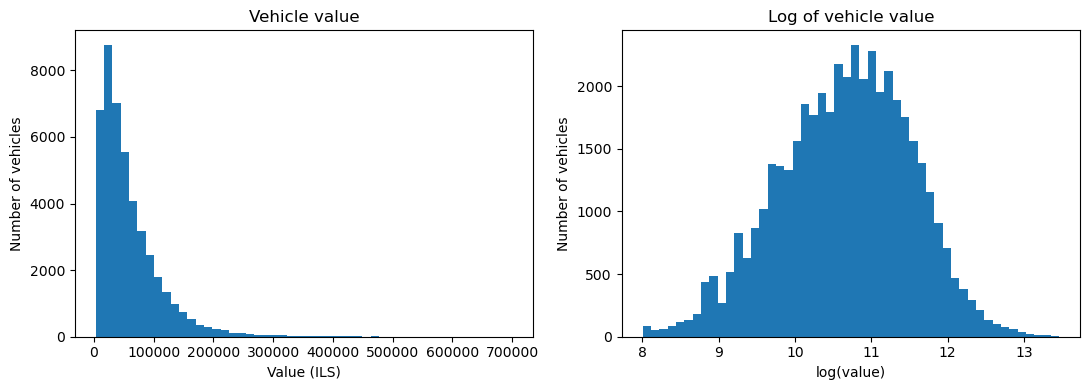

In [18]:
# היסטוגרמה של שווי הרכב בסקאלה רגילה ובסקאלה לוגריתמית
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(value_fixed, bins=50)
axes[0].set_title("Vehicle value")
axes[0].set_xlabel("Value (ILS)")
axes[0].set_ylabel("Number of vehicles")

axes[1].hist(np.log(value_fixed), bins=50)
axes[1].set_title("Log of vehicle value")
axes[1].set_xlabel("log(value)")
axes[1].set_ylabel("Number of vehicles")
plt.tight_layout()
plt.show()

בסקאלה לוגריתמית ההתפלגות כמעט סימטרית, ולכן הלוגריתם מתאים יותר למודל הלינארי.

## עמודה R: safety_features_count

מספר מערכות הבטיחות ברכב, כריות אוויר ובלימת חירום, בטווח 0 עד 8 לפי מילון השדות. זו עמודה מספרית שידועה ביום החתימה.

נבדוק שכל הערכים בטווח החוקי, האם הערכים הגיוניים לפי סוג הרכב, ואת הקשר לעלות התביעות.

In [19]:
# בדיקת ערכים חסרים ומספר הרכבים לכל מספר מערכות בטיחות
print("Missing:", df["safety_features_count"].isna().sum())
print("Out of range:", ((df["safety_features_count"] < 0) | (df["safety_features_count"] > 8)).sum())
df["safety_features_count"].value_counts().sort_index()

Missing: 0
Out of range: 0


safety_features_count
0    1786
1    3569
2    7408
3    6051
4    6598
5    7390
6    6892
7    4428
8     878
Name: count, dtype: int64

In [20]:
# בדיקה האם מספר מערכות הבטיחות הגיוני לפי סוג הרכב
df.groupby("vehicle_type")["safety_features_count"].agg(["min", "median", "max"])

,min,median,max
vehicle_type,,,
motorcycle,0,2.0,3
pickup,0,4.0,8
sedan,0,4.0,8
small,0,4.0,8
sports,0,4.0,8
suv,0,4.0,8


In [21]:
# השוואת עלות התביעות לפי מספר מערכות הבטיחות
df.groupby("safety_features_count")["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
safety_features_count,,,,
0,1921.282,0.467,0.039,1786
1,1990.914,0.408,0.042,3569
2,2251.506,0.397,0.056,7408
3,2870.021,0.382,0.081,6051
4,3000.585,0.340,0.093,6598
5,3524.230,0.318,0.113,7390
6,3784.361,0.311,0.128,6892
7,3780.528,0.285,0.129,4428
8,4602.868,0.281,0.148,878


נבדוק האם עמודת מערכות הבטיחות היא רק גיל הרכב במסווה, על ידי השוואה מול אחוז התובעים

In [22]:
# הקשר בין מערכות הבטיחות לגיל הרכב, ואחוז הנהגים שתובעים לפי שילוב של שניהם
print("Correlation with vehicle age:", round(df["safety_features_count"].corr(df["vehicle_age"]), 3))

age_group = pd.qcut(df["vehicle_age"], 5)
safety_group = pd.cut(df["safety_features_count"], bins=[-1, 2, 5, 8])
df.pivot_table(index=age_group, columns=safety_group, values="annual_claim_cost",
               aggfunc=lambda s: (s > 0).mean(), observed=True).round(3)

Correlation with vehicle age: -0.807


safety_features_count,"(-1, 2]","(2, 5]","(5, 8]"
vehicle_age,,,
"(-0.001, 3.0]",0.442,0.334,0.295
"(3.0, 5.0]",0.492,0.339,0.307
"(5.0, 8.0]",0.374,0.337,NaN
"(8.0, 12.0]",0.397,0.367,NaN
"(12.0, 25.0]",0.415,0.600,NaN


אנחנו רואים עליה במס' התובעים בקבוצת הרכבים הישנים עם יותר מערכות בטיחות, נבדוק כמה רכבים יש בכל משבצת

In [23]:
# מספר הרכבים בכל משבצת, כדי לדעת על אילו אחוזים אפשר לסמוך
df.pivot_table(index=age_group, columns=safety_group, values="annual_claim_cost",
               aggfunc="count", observed=True)

safety_features_count,"(-1, 2]","(2, 5]","(5, 8]"
vehicle_age,,,
"(-0.001, 3.0]",319.0,2216.0,7983.0
"(3.0, 5.0]",463.0,3597.0,4215.0
"(5.0, 8.0]",1158.0,9199.0,NaN
"(8.0, 12.0]",3420.0,5022.0,NaN
"(12.0, 25.0]",7403.0,5.0,NaN


### מסקנה לגבי safety_features_count
העמודה נקייה, ללא ערכים חסרים וכל הערכים בטווח החוקי 0 עד 8. אצל אופנועים יש 0 עד 3 מערכות, ובשאר הסוגים 0 עד 8, זה הגיוני.

יותר מערכות בטיחות פירושן פחות תביעות אך יקרות יותר: אחוז התביעות יורד מ-46.7% ל-28.1%, ואחוז הנהגים היקרים עולה מ-3.9% ל-14.8%. העלות הממוצעת עולה פי 2.4.

הסיבה היא משתנה מבלבל: הקורלציה עם גיל הרכב היא 0.807-, כי רכבים חדשים ויקרים מגיעים עם יותר מערכות. אין בדאטה רכבים ישנים עם 6 מערכות ומעלה.

גם לגבי רכבים באותו גיל, יותר מערכות בטיחות מורידות את אחוז התביעות. למשל, ברכבים בני 0 עד 3 האחוז יורד מ-44% ל-30%. לכן העמודה תישאר. חריג אחד בטבלה מבוסס על 5 רכבים בלבד ולכן אינו אמין.

חוק: ערך שאינו מספר או מחוץ לטווח 0 עד 8 הופך לחסר.

## עמודה S: has_telematics
האם מותקנת ברכב קופסה שחורה או אפליקציית מעקב. לפי מילון השדות 1 פירושו כן ו-0 פירושו לא. זו עמודה שידועה ביום החתימה.

נבדוק שהעמודה מכילה רק את שני הערכים החוקיים ואת הקשר לעלות התביעות.

In [24]:
# בדיקת ערכים חסרים וכל הערכים השונים בעמודה
print("Missing:", df["has_telematics"].isna().sum())
df["has_telematics"].value_counts().sort_index()

Missing: 0


has_telematics
0    36367
1     7997
2      636
Name: count, dtype: int64

In [25]:
# השוואה בין שלושת הערכים בעלות התביעות ובגיל הנהג
df.groupby("has_telematics").agg(
    avg_cost=("annual_claim_cost", "mean"),
    share_with_claim=("annual_claim_cost", lambda s: (s > 0).mean()),
    avg_driver_age=("driver_age", "mean"),
    drivers=("annual_claim_cost", "count"),
).round(3)

,avg_cost,share_with_claim,avg_driver_age,drivers
has_telematics,,,,
0,2963.389,0.347,48.777,36367
1,3433.148,0.371,44.526,7997
2,3244.351,0.355,47.995,636


נבדוק האם יש קשר בין מדינה מסוימת למילוי של "2" בטופס

In [26]:
# אחוז הרכבים עם הערך 2 בכל מדינה, כדי לבדוק אם זו תקלה במקור מסוים
(df["has_telematics"] == 2).groupby(df["country"]).mean().round(3).sort_values()

country
JP    0.009
US    0.012
PL    0.013
BR    0.013
GB    0.014
IT    0.014
DE    0.015
ES    0.016
IL    0.016
FR    0.017
Name: has_telematics, dtype: float64

### מסקנה לגבי has_telematics
לפי מילון השדות העמודה אמורה להכיל רק 0 ו-1, אך ב-636 רכבים מופיע הערך 2. הערך מפוזר באופן אחיד בין המדינות (0.9% עד 1.7%), ולכן אינו תקלה של מקור אחד.

נראה שהנהגים עם הערך 2 מפוזרים בדאטה, הגיל הממוצע שלהם (48.0) זהה לממוצע המשוקלל של קבוצות 0 ו-1, והעלות שלהם באמצע. לכן השערה שלנו היא ש-2 פירושו "לא ידוע", והוא יהפוך לחסר.

נהגים עם אמצעי מעקב יקרים ב-16% מנהגים בלי מעקב, וצעירים יותר בממוצע (44.5 לעומת 48.8). כנראה שזו השפעה של בחירה ולא של המעקב עצמו: נהגים צעירים או מסוכנים יותר מתקינים מעקב, או שהחברה דורשת זאת מהם. העמודה תישאר.

חוק: ערך שאינו 0 או 1 הופך לחסר.

## עמודה T: usage_type
.זו עמודה קטגוריאלית שהנהג ממלא בטופס ולכן ידועה ביום החתימה
סוג השימוש העיקרי ברכב: 

נסיעה לעבודה (commute), עבודה מנהלתית (admin_work), טיולים ופנאי (leisure), נהיגה מקצועית (professional) ומשלוחים (delivery)

נבדוק את אחידות הערכים ואת הקשר לעלות התביעות, ונבדוק את ההשערה מעמודה vehicle_type לגבי הטנדרים.

In [27]:
# בדיקת ערכים חסרים ורשימת סוגי השימוש עם מספר הנהגים בכל אחד
print("Missing:", df["usage_type"].isna().sum())
df["usage_type"].value_counts()

Missing: 0


usage_type
commute         18600
leisure         14265
admin_work       6226
delivery         3406
professional     2503
Name: count, dtype: int64

In [28]:
# השוואת עלות התביעות בין סוגי השימוש לפי שלושה מדדים
df.groupby("usage_type")["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3).sort_values("avg_cost")

,avg_cost,share_with_claim,share_expensive,drivers
usage_type,,,,
admin_work,2014.520,0.272,0.060,6226
leisure,2351.470,0.269,0.070,14265
commute,2892.270,0.356,0.087,18600
delivery,5945.473,0.645,0.187,3406
professional,6853.875,0.575,0.213,2503


כעת נבדוק את ההשערה שהעלינו כשבדקנו את עמודת vehicle_type

האם סוג הרכב, למשל טנדרים, מושפע גם מסוג השימוש?

In [29]:
# עלות ממוצעת לפי שילוב של סוג רכב וסוג שימוש, כדי לבדוק אם הטנדרים יקרים רק בגלל השימוש בהם
df.pivot_table(index="vehicle_type", columns="usage_type",
               values="annual_claim_cost", aggfunc="mean").round(0)

usage_type,admin_work,commute,delivery,leisure,professional
vehicle_type,,,,,
motorcycle,1809.0,2400.0,5395.0,1869.0,3560.0
pickup,4175.0,5563.0,12914.0,4301.0,11280.0
sedan,1761.0,2474.0,5254.0,1978.0,5636.0
small,773.0,1084.0,2811.0,906.0,2405.0
sports,5880.0,8717.0,19303.0,7772.0,15644.0
suv,2515.0,3834.0,8525.0,3019.0,9675.0


### מסקנה לגבי usage_type
העמודה נקייה, עם חמישה סוגי שימוש בפורמט אחיד וללא ערכים חסרים. יש הבדל גדול בעלות, פי 3.4 בין עבודה מנהלתית לנהיגה מקצועית. במשלוחים התדירות הגבוהה ביותר (64.5% תובעים, לעומת 27% בפנאי), ובנהיגה מקצועית הכי הרבה נהגים יקרים (21.3%).

בדקנו את ההשערה מעמודה vehicle_type, 

שהטנדרים יקרים בגלל סוג השימוש בהם. ההשערה לא נתמכה: בתוך כל סוג שימוש טנדר עולה פי 2.2 עד 2.5 מסדאן. מנגד, בתוך כל סוג רכב, משלוחים ונהיגה מקצועית יקרים פי 2 עד 3 מעבודה מנהלתית. לכן לכל אחת משתי העמודות יש השפעה משלה, ושתיהן יישארו.

חלק מהצירופים מבוססים על מעט נהגים, למשל רכבי ספורט במשלוחים (17 נהגים), ולכן אינם אמינים.

חוק: איחוד כתיבה, וערך שאינו אחד מחמשת הסוגים החוקיים הופך לחסר.

## עמודה U: annual_km_estimated
מספר הקילומטרים השנתי, כפי שהנהג דיווח בטופס. לפי מילון השדות הערך חסר אצל חלק מהנהגים. זו עמודה שידועה ביום החתימה, כי היא הערכה של הנהג ולא מדידה בסוף השנה.

נבדוק ערכים חסרים וערכים לא הגיוניים, את הסיבה לחוסרים, האם החוסר עצמו קשור לעלות, ואת הקשר בין הקילומטרים לעלות.

In [33]:
# בדיקת ערכים חסרים וסטטיסטיקה תיאורית של הקילומטרים השנתיים
print("Missing:", df["annual_km_estimated"].isna().sum())
df["annual_km_estimated"].describe().round(0)

Missing: 4311


count     40689.0
mean      45750.0
std      179466.0
min         500.0
25%        6000.0
50%       10000.0
75%       16000.0
max      999999.0
Name: annual_km_estimated, dtype: float64

In [34]:
# כמה נהגים בדיוק בערך 999999, והערכים הגבוהים ביותר מלבדו
print("Drivers at 999999:", (df["annual_km_estimated"] == 999999).sum())
km_real = df["annual_km_estimated"].replace(999999, np.nan)
print("Largest real values:", km_real.sort_values(ascending=False).head(5).values)
km_real.describe().round(0)

Drivers at 999999: 1386
Largest real values: [120000. 120000. 120000. 120000. 114500.]


count     39303.0
mean      12098.0
std        9946.0
min         500.0
25%        6000.0
50%        9500.0
75%       15000.0
max      120000.0
Name: annual_km_estimated, dtype: float64

בלי הערך 999999 הנתונים הגיוניים: 500 עד 120,000 ק"מ, וחציון של 9,500. יש לנו שני סוגים של חוסר: ערכים חסרים רגילים והערך 999999. נבדוק אם שני הסוגים מתנהגים אותו דבר, ואם החוסר עצמו קשור לעלות.

In [35]:
# השוואת עלות התביעות בין נהגים שדיווחו קילומטרים, נהגים שהערך שלהם חסר, ונהגים עם הערך 999999
km_status = pd.Series("reported", index=df.index)
km_status[df["annual_km_estimated"].isna()] = "missing"
km_status[df["annual_km_estimated"] == 999999] = "999999"

df.groupby(km_status)["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
999999,5258.494,0.495,0.154,1386
missing,5133.800,0.518,0.161,4311
reported,2744.518,0.328,0.083,39303


שתי קבוצות החסר כמעט זהות, ולכן נאחד אותן. 

נהגים שלא דיווחו יקרים פי 1.9 ממי שדיווח, כלומר החוסר עצמו מנבא. 

נבדוק למה הערך חסר: אם החוסר מוסבר על ידי עמודה אחרת, כמו סוג השימוש, זה MAR. אם הוא קשור לערך עצמו, למשל נהגים שנוסעים הרבה מעדיפים לא לדווח, זה MNAR.

In [36]:
# אחוז הנהגים שלא דיווחו קילומטרים בכל סוג שימוש
(km_status != "reported").groupby(df["usage_type"]).mean().round(3).sort_values()

usage_type
leisure         0.047
admin_work      0.064
commute         0.095
delivery        0.459
professional    0.522
dtype: float64

החוסר מרוכז בשליחים ובנהגים מקצועיים, כמחצית מהם לא דיווחו. 

כלומר, רוב החוסר מוסבר בסוג השימוש - MAR. 

נבדוק אם גם בתוך אותו סוג שימוש מי שלא דיווח יקר יותר. אם כן, יש בחוסר מידע מעבר לסוג השימוש.

In [37]:
# עלות ממוצעת לפי סוג שימוש, בנפרד לנהגים שדיווחו ולנהגים שלא דיווחו
df.pivot_table(index=df["usage_type"], columns=(km_status != "reported").rename("not_reported"),
               values="annual_claim_cost", aggfunc="mean").round(0)

not_reported,False,True
usage_type,,
admin_work,1970.0,2666.0
commute,2845.0,3350.0
delivery,5668.0,6272.0
leisure,2299.0,3409.0
professional,5667.0,7942.0


גם בתוך כל סוג שימוש מי שלא דיווח יקר יותר, ולכן לחוסר יש מידע משלו, והמודל יקבל עמודת סימון חוסר. 

כעת נבדוק את הקשר בין הקילומטרים לעלות, רק אצל מי שדיווח.

In [38]:
# חלוקת הנהגים שדיווחו לחמש קבוצות שוות לפי הקילומטרים והשוואת עלות התביעות בין הקבוצות
km_group = pd.qcut(km_real, 5)
df.groupby(km_group, observed=True)["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
annual_km_estimated,,,,
"(499.999, 5000.0]",1419.772,0.209,0.037,8231
"(5000.0, 8000.0]",1931.082,0.271,0.054,8460
"(8000.0, 11500.0]",2517.748,0.311,0.074,7830
"(11500.0, 17000.0]",3030.018,0.368,0.095,7289
"(17000.0, 120000.0]",5077.396,0.500,0.163,7493


### מסקנה לגבי annual_km_estimated
בעמודה שני סוגים של ערכים חסרים: 4,311 ערכים חסרים, ועוד 1,386 נהגים עם הערך 999999, שהוא חסר מוסווה. הוא ניפח את הממוצע ל-45,750. בלעדיו הטווח הוא 500 עד 120,000 ק"מ, עם חציון של 9,500, וזה הגיוני.

שתי קבוצות החוסר מתנהגות כמעט זהה (עלות של 5,258 ו-5,134), ולכן אוחדו. בסך הכול 5,697 נהגים (12.7%) לא דיווחו, והם יקרים פי 1.9 ממי שדיווח, גם בתדירות (51% מול 33%) וגם בחומרה. כלומר, החוסר עצמו מנבא.

רוב החוסר מוסבר בסוג השימוש (MAR): כמחצית מהשליחים ומהנהגים המקצועיים לא דיווחו, לעומת 5% עד 10% בשאר הסוגים. אך גם בתוך אותו סוג שימוש מי שלא דיווח יקר יותר, למשל בפנאי 3,409 מול 2,299. ייתכן שיש כאן גם רכיב של MNAR: נהגים שנוסעים הרבה מעדיפים לא לדווח. אי אפשר לבדוק את זה, כי הערך האמיתי חסר

אצל מי שדיווח, כמה שנוסעים יותר העלות עולה פי 3.6, בעיקר בתדירות (21% עד 50% תובעים). גם אחוז הנהגים היקרים עולה, בין השאר כי העלות היא סך התביעות בשנה, ומי שנוסע הרבה צובר יותר תביעות.

חוק: ערך שאינו חיובי או מעל 200,000 הופך לחסר. ההשלמה תיעשה ב-Pipeline לפי החציון, עם עמודת סימון חוסר. העמודה רלוונטית גם לסעיף 7, בחתך "דיווחו מול לא דיווחו".

## פונקציות עזר

In [30]:
# פונקציות עזר לניקוי: אחת לעמודות מספר ואחת לעמודות טקסט, שעובדות גם על עמודה ריקה לגמרי
def to_num(s):
    # המרה למספר אחרי הסרת פסיקים ורווחים, וערך אינסופי הופך לחסר
    out = pd.to_numeric(s.astype(str).str.replace(",", "", regex=False).str.strip(), errors="coerce")
    return out.replace([np.inf, -np.inf], np.nan)

def clean_text(s, case="lower"):
    # הסרת רווחים ואחידות אותיות, וערך חסר או מחרוזת ריקה הופכים לחסר
    out = s.astype(str).str.strip()
    out = out.str.upper() if case == "upper" else out.str.lower()
    return out.where(s.notna() & (out != ""))

## פונקציית הניקוי

In [39]:
# פונקציית הניקוי של עמודות הרכב והשימוש שנוסיף לה חוק אחרי כל עמודה שנבדוק
def clean_vehicle_cols(df):
    df = df.copy()

    # סוג רכב: איחוד כתיבה, וערך שאינו אחד מששת הסוגים החוקיים הופך לחסר
    valid_vehicle = ["small", "sedan", "suv", "sports", "pickup", "motorcycle"]
    df["vehicle_type"] = clean_text(df["vehicle_type"], case="lower")
    df.loc[~df["vehicle_type"].isin(valid_vehicle), "vehicle_type"] = np.nan

    # גיל רכב: ערך שלילי הופך לחסר, וערך מעל עשרים וחמש הופך לעשרים וחמש
    df["vehicle_age"] = to_num(df["vehicle_age"])
    df.loc[df["vehicle_age"] < 0, "vehicle_age"] = np.nan
    df["vehicle_age"] = df["vehicle_age"].clip(upper=25)

    # עוצמת מנוע: ערך שאינו חיובי הופך לחסר
    df["engine_hp"] = to_num(df["engine_hp"])
    df.loc[df["engine_hp"] <= 0, "engine_hp"] = np.nan

    # שווי רכב: הפסיקים מוסרים בפונקציית העזר, וערך שאינו חיובי הופך לחסר
    df["vehicle_value"] = to_num(df["vehicle_value"])
    df.loc[df["vehicle_value"] <= 0, "vehicle_value"] = np.nan

    # מערכות בטיחות: ערך מחוץ לטווח אפס עד שמונה הופך לחסר
    df["safety_features_count"] = to_num(df["safety_features_count"])
    df.loc[(df["safety_features_count"] < 0) | (df["safety_features_count"] > 8), "safety_features_count"] = np.nan

    # טלמטיקה: ערך שאינו אפס או אחד הופך לחסר
    df["has_telematics"] = to_num(df["has_telematics"])
    df.loc[~df["has_telematics"].isin([0, 1]), "has_telematics"] = np.nan

    # סוג שימוש: איחוד כתיבה, וערך שאינו אחד מחמשת הסוגים החוקיים הופך לחסר
    valid_usage = ["commute", "admin_work", "leisure", "professional", "delivery"]
    df["usage_type"] = clean_text(df["usage_type"], case="lower")
    df.loc[~df["usage_type"].isin(valid_usage), "usage_type"] = np.nan

    # קילומטרים: ערך שאינו חיובי או מעל מאתיים אלף הופך לחסר, כולל הערך המוסווה של תשע מאות תשעים ותשעה אלף
    df["annual_km_estimated"] = to_num(df["annual_km_estimated"])
    df.loc[(df["annual_km_estimated"] <= 0) | (df["annual_km_estimated"] > 200000), "annual_km_estimated"] = np.nan
    
    return df

# בדיקה שהפונקציה רצה על כל הדאטה ועל שורה בודדת
print(clean_vehicle_cols(df).shape)
print(clean_vehicle_cols(df.iloc[[0]]).shape)

(45000, 30)
(1, 30)
